In [ ]:
pip install together

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.4/86.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.3/120.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 2.5 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.20.0
    Uninstalling typer-0.20.0:
      Successfully uninstalled typer-0.20.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pickle
import random
import re
import json
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, clear_output
from tqdm import tqdm
from together import Together
from sklearn.metrics import classification_report
from collections import Counter

In [ ]:
#MODEL_NAME = "Qwen/Qwen3-235B-A22B-Instruct-2507-tput"
MODEL_NAME = "moonshotai/Kimi-K2-Instruct-0905"
#MODEL_NAME = "Qwen/Qwen3-Next-80B-A3B-Instruct"
API_KEY = 'xxx'

client = Together(api_key=API_KEY)

# ================= PROMPT =================
ANALYSIS_PROMPT = '''
# Role
You are an expert logical analyst. Your task is to classify reasoning strategies in AI thinking traces for logical deduction tasks,
where the AI needs to use a certain strategy infer ground truth variables (e.g., A, B) from a logic function (e.g., XOR) using experimental trials (e.g., V0=1, V1=1... result=1).

## 1. Permutation (Systematic/Heuristic Search)
- **Core Logic:** The model identifies the solution by testing specific hypotheses (variable pairs) against data points, one by one or in small batches.
- **Key Indicators:**
    - Examples："Let's test V0 and V1... Next, let's try V2 and V3..."
    - If the model uses trials to narrow down candidates，and then proceeds to verify remaining pairs individually, it is Elimination.
    - If the agent tests a pair, fails, and immediately moves to the "next available pair" in a sequence, it is Permutation.
- **Label:** "permutation"

## 2. Elimination (Deductive Pruning)
- **Core Logic:** The model uses "Logical Pruning." It derives a general rule from the trial data that pre-emptively removes candidate(s) from consideration.
- **Key Indicators:**
    - Examples：
      "Trial X is 0, and V1 and V2 are 1, therefore NONE of these can be part of the solution. I can now ignore all pairs involving V1 and V2." (remove multiple candidates)
      "Trial X is 1, so the combination V0 and V1 can not be true." (remove one candidate)
    - If the pair was extracted from data features (e.g., "Trial 2 is the only positive outcome, and only V1 and V4 are 1 there, so it MUST be them"), it is Elimination.
    - Elimination happen **before** or **during** the search to narrow the search space. Simply checking if a found answer is correct is NOT elimination.
- **Label:** "elimination"

## 3. None
- Provide the direct answer (with or without explaination) without any explicit strategy shown.
- **Label:** "none"

# Example 1
- **Case A:** Model says "V1 is in a 0-result trial, so V1 is out. Now I'll test the remaining (V0, V2), (V0, V3)..." -> **Label: elimination** (Reason: Pruning occurred).
- **Case B:** Model says "Trial 1 is 1, maybe it's V1 and V2? Let's check V1+V2. Yes! It works." -> **Label: permutation** (Reason: Hypothesize-and-test, no pruning).

# Example 2
- **Case A:** Model says "Is it V0 and V1? Trial 1 says result is 0, so no. Let's try V0 and V2." -> **Label: permutation** (Reason: It picks a pair first, then checks it.)
- **Case B:** Model says "Trial 1 has V0, V1 and result is 0. This means neither V0 nor V1 can be the active variable. Therefore, the only remaining candidate is V2." -> **Label: elimination** (Reason: It uses the trial to kill candidates first, even if it only kills one or two.)

# Output Requirements
- Focus on the **process**, not the correctness of the answer.
- Provide a brief reasoning_analysis explaining the "why".
- Return ONLY a JSON object:
{
  "reasoning_analysis": "A concise explanation of why this fits the chosen label.",
  "strategy_type": "permutation" | "elimination" | "none"
}

# Input Trace
<thinking_trace>
{{THINKING_TRACE}}
</thinking_trace>
'''

def run_llm_judge(annotations):

    results = []
    print(f"🚀 LLM Judge is analyzing {len(annotations)} samples...")
    for item in tqdm(annotations):
        prompt = ANALYSIS_PROMPT.replace("{{THINKING_TRACE}}", item['content'])
        try:
            res = client.chat.completions.create(model=MODEL_NAME, messages=[{"role": "user", "content": prompt}], temperature=0.1)
            raw_out = res.choices[0].message.content
            # JSON extraction
            match = re.search(r'\{.*\}', raw_out, re.DOTALL)
            analysis = json.loads(match.group(0)) if match else {"strategy_type": "none"}

            results.append({
                'ground_truth': item['label'].replace('invalid/none', 'none'),
                'prediction': analysis.get('strategy_type', 'none'),
                'type': item['type'],
                'content': item['content']
            })

        except Exception as e:
            print(f"Error: {e}")
    return pd.DataFrame(results)

def get_single_prediction(content):
    
    prompt = ANALYSIS_PROMPT.replace("{{THINKING_TRACE}}", content)
    try:
        res = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[{"role": "user", "content": prompt}],
            temperature=0.3  
        )
        raw_out = res.choices[0].message.content
        match = re.search(r'\{.*\}', raw_out, re.DOTALL)
        if match:
            analysis = json.loads(match.group(0))
            return analysis.get('strategy_type', 'none')
    except Exception as e:
        print(f"Request Error: {e}")
    return "none"

def run_llm_judge_majority_vote(annotations):
    results = []
    print(f"🚀 LLM Judge (Majority Vote Mode) is analyzing {len(annotations)} samples...")

    for item in tqdm(annotations):
        votes = []
        final_prediction = "none"

        # Dynamic voting cycle: minimum 3 times, maximum 7 times
        for i in range(1, 8):
            pred = get_single_prediction(item['content'])
            votes.append(pred)

            # Starting from the 3rd check, check if a majority has been reached.
            if i >= 3:
                counts = Counter(votes)
                most_common_val, count = counts.most_common(1)[0]

                # Judgment Criteria: More than half the votes (Early Stop)
                # 2 out of 3 times, 3 out of 4 times, 3 out of 5 times...
                if count > i / 2:
                    final_prediction = most_common_val
                    break

            # If it's not halfway through by the 7th time (very rare, unless it's 3-2-2), take the highest result.
            if i == 7:
                final_prediction = Counter(votes).most_common(1)[0][0]

        results.append({
            'ground_truth': item['label'].replace('invalid/none', 'none'),
            'prediction': final_prediction,
            'vote_history': "|".join(votes), 
            'total_votes': len(votes),
            'type': item['type'],
            'content': item['content']
        })

    return pd.DataFrame(results)


def visualize_results(df):
    #plt.style.use('seaborn-v0_8')
    #fig, ax = plt.subplots(1, 1, figsize=(10, 5))
    #sns.histplot(data=df, x='confidence', hue='ground_truth', kde=True, ax=ax, palette='viridis')
    #ax.set_title("Confidence Distribution by Strategy")
    #plt.show()

    print("\n" + "="*40 + "\nCLARITY REPORT\n" + "="*40)
    print(classification_report(df['ground_truth'], df['prediction']))

    errors = df[df['ground_truth'] != df['prediction']]
    print(f"\n❌ FOUND {len(errors)} MISMATCHES:")
    for _, row in errors.head(5).iterrows():
        print(f"[{row['type'].upper()}] GT: {row['ground_truth']} | Pred: {row['prediction']}")
        print(f"Text: {row['content'][:150]}...\n" + "-"*20)

In [ ]:
results_df.to_csv(f"/content/drive/MyDrive/inference-time-scale-adaptation/llm_judge_eval/eval_data_majority_vote.csv", index=False)

In [ ]:
with open('/content/drive/MyDrive/inference-time-scale-adaptation/llm_judge_eval/annotations_100.json', 'r') as f:
    annotations = json.load(f)
results_df = run_llm_judge_majority_vote(annotations)
visualize_results(results_df)

🚀 LLM Judge (Majority Vote Mode) is analyzing 100 samples...


100%|██████████| 100/100 [11:45<00:00,  7.06s/it]


CLARITY REPORT
              precision    recall  f1-score   support

 elimination       0.93      0.83      0.88        52
 permutation       0.83      0.94      0.88        48

    accuracy                           0.88       100
   macro avg       0.88      0.88      0.88       100
weighted avg       0.89      0.88      0.88       100


❌ FOUND 12 MISMATCHES:
[THINK] GT: elimination | Pred: permutation
Text: First, the hypothesis is that the outcome is determined by a hidden function: A XOR B, where A and B are two of the variables from V0 to V11. XOR mean...
--------------------
[THINK] GT: elimination | Pred: permutation
Text: First, the hypothesis is that the outcome is determined by a hidden function: ((NOT A) AND (NOT B)). This means that the outcome should be 1 only when...
--------------------
[THINK] GT: elimination | Pred: permutation
Text: First, the hypothesis is that the outcome is determined by a hidden function: (NOT A) AND (NOT B). That means the outcome should be 1

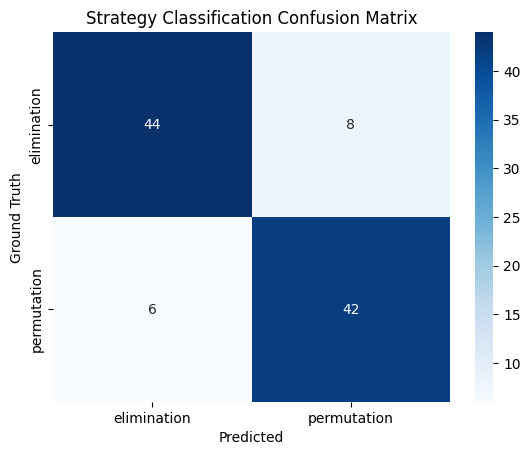

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

labels = ['elimination', 'permutation']
cm = confusion_matrix(results_df_['ground_truth'], results_df_['prediction'], labels=labels)

sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Ground Truth')
plt.title('Strategy Classification Confusion Matrix')
plt.show()

In [10]:
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(results_df['ground_truth'], results_df['prediction'])
print(f"Cohen's Kappa: {kappa:.3f}")

Cohen's Kappa: 0.761


In [ ]:
results_df_.to_csv(f"/content/drive/MyDrive/inference-time-scale-adaptation/llm_judge_eval/eval_data_round_3.csv", index=False)

In [ ]:
with open('/content/drive/MyDrive/inference-time-scale-adaptation/llm_judge_eval/annotations_100.json', 'r') as f:
    annotations = json.load(f)
results_df_ = run_llm_judge(annotations)
visualize_results(results_df_)

🚀 LLM Judge is analyzing 100 samples...


100%|██████████| 100/100 [04:09<00:00,  2.50s/it]


CLARITY REPORT
              precision    recall  f1-score   support

 elimination       0.88      0.85      0.86        52
 permutation       0.84      0.88      0.86        48

    accuracy                           0.86       100
   macro avg       0.86      0.86      0.86       100
weighted avg       0.86      0.86      0.86       100


❌ FOUND 14 MISMATCHES:
[THINK] GT: elimination | Pred: permutation
Text: First, the hypothesis is that the outcome is determined by a hidden function: A XOR B, where A and B are two of the variables from V0 to V11. XOR mean...
--------------------
[THINK] GT: elimination | Pred: permutation
Text: First, the hypothesis is that the outcome is determined by a hidden function: ((NOT A) AND (NOT B)). This means that the outcome should be 1 only when...
--------------------
[THINK] GT: elimination | Pred: permutation
Text: First, the hypothesis is that the outcome is determined by a hidden function: (NOT A) AND (NOT B). That means the outcome should be 1

In [46]:
# 筛选出所有预测与标注不符的样本
error_cases = results_df_[results_df_['ground_truth'] != results_df_['prediction']]

print(f"🔍 Found {len(error_cases)} discrepancy cases out of {len(results_df_)} samples.\n")

for i, row in error_cases.iterrows():
    print("="*60)
    print(f"CASE ID: {i} | Type: {row['type']}")
    print(f"LABEL (Human): {row['ground_truth'].upper()}")
    print(f"PRED  (LLM)  : {row['prediction'].upper()}")
    print("-"*60)

    # 打印前 500 个字符（约 100 词左右，逻辑点通常在开头）
    # 如果想精确打印 500 词，可以用 row['content'].split()[:500]
    content_snippet = " ".join(row['content'].split()[:500])
    print(f"CONTENT SNIPPET:\n{content_snippet}...")
    print("="*60 + "\n")

🔍 Found 12 discrepancy cases out of 100 samples.

CASE ID: 10 | Type: think
LABEL (Human): ELIMINATION
PRED  (LLM)  : PERMUTATION
------------------------------------------------------------
CONTENT SNIPPET:
First, the hypothesis is that the outcome is determined by a hidden function: A XOR B, where A and B are two of the variables from V0 to V11. XOR means exclusive or, which is 1 if A and B are different, and 0 if they are the same. I need to find which two variables A and B are such that for each trial, Outcome = A XOR B. There are 12 variables, so there are many possible pairs to check. But I have 10 trials, so I can use the data to test different pairs. Since XOR is symmetric, I don't need to worry about order; {V_i, V_j} is the same as {V_j, V_i}. I should list all the trials with their outcomes and see for which pair A XOR B matches the outcome in every trial. Let me make a table for easier reference. I'll denote the variables as columns and trials as rows. Variables: V0 to V11.